# Lucrare de laborator nr. 2
## Autoencoder pe baza setului de date MNIST

## Scop și obiective

Autoencoderul învață să refacă datele primite. Encoderul comprimă imaginea într-un cod mai scurt, iar Decoderul reconstruiește imaginea din acel cod.

1. Încărcarea MNIST și explorarea datelor.
2. Preprocesarea imaginilor.
3. Construirea Encoderului, Decoderului și a modelului complet.
4. Compilarea și antrenarea Autoencoderului.
5. Compararea loss-ului și a imaginilor reconstruite.
6. Analizarea codului latent, a rezultatelor și formularea concluziilor.


## Partea teoretică

**Autoencoder:** rețea neuronală care învață să reconstruiască datele de intrare.

**Imagine originală → Encoder → reprezentare latentă (cod latent) → Decoder → imagine reconstruită**

Encoderul transformă imaginea într-o reprezentare compactă (*latent representation*, *latent vector*). Decoderul transformă această reprezentare înapoi într-o imagine. MNIST are imagini grayscale de 28 × 28 pixeli, adică 784 valori; comprimarea poate păstra trăsăturile importante, dar poate pierde detalii.

Folosim MSE (Mean Squared Error), media diferențelor pătratice dintre pixelii originali și reconstruiți. Un loss mai mic înseamnă diferențe numerice mai mici. MNIST conține cifre de la 0 la 9 și este împărțit în imagini de antrenare și test.


### Autoencoder variational (VAE)
Un VAE învață pentru fiecare imagine o distribuție latentă, descrisă prin media `z_mean` și log-varianța `z_log_var`. 
- z_mean = centrul zonei.
- z_log_var = cât de larg e norul în jurul centrului.


Eșantionarea: alegem un punct random din acea zonă:
* z = z_mean + exp(0.5 * z_log_var) * epsilon
- epsilon = zgomot random.
- Formula înseamnă: centru + o mică abatere random.
- Motivul: așa rețeaua poate fi antrenată chiar dacă există random în ea (reparametrizare).


În comparația practică păstrăm Autoencoderul clasic deja antrenat și adăugăm un VAE cu latent dimensiune 2, ca spațiul să poată fi reprezentat într-un plan și eșantionat ușor.

VAE are de făcut două lucruri deodată, deci are două penalizări:
- Eroarea de reconstrucție: imaginea refăcută trebuie să semene cu originalul.
- Divergența KL: zonele din spațiul latent trebuie să rămână aproape de o distribuție normală standard, adică ordonate, fără să se împrăștie haotic.

- Rezultatul: spațiul latent devine „organizat". Putem alege un punct random, îl dăm decoderului și obținem o cifră nouă.




## 1. Importuri și reproductibilitate

Seed-ul fixează sursele principale de aleatoriu pentru a face rulările mai ușor de repetat; mediile diferite pot produce mici variații.

In [73]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print(f"Versiunea TensorFlow utilizată: {tf.__version__}")

Versiunea TensorFlow utilizată: 2.22.0-rc0


## 2. Încărcarea setului MNIST

Etichetele indică cifra, dar modelul de reconstrucție va învăța din imagini fără să folosească etichetele ca ținte.

In [74]:
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
print(f"Forma imaginilor de antrenare: {train_images.shape}")
print(f"Forma etichetelor de antrenare: {train_labels.shape}")
print(f"Forma imaginilor de test: {test_images.shape}")
print(f"Forma etichetelor de test: {test_labels.shape}")
print(f"Numărul imaginilor de antrenare: {len(train_images)}")
print(f"Numărul imaginilor de test: {len(test_images)}")

Forma imaginilor de antrenare: (60000, 28, 28)
Forma etichetelor de antrenare: (60000,)
Forma imaginilor de test: (10000, 28, 28)
Forma etichetelor de test: (10000,)
Numărul imaginilor de antrenare: 60000
Numărul imaginilor de test: 10000


## 3. Explorarea imaginilor

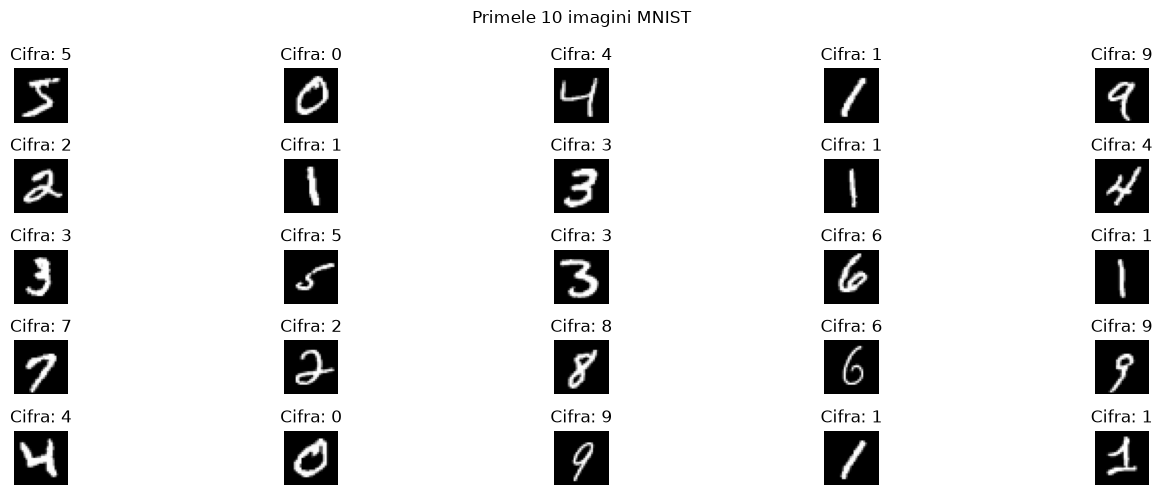

In [75]:
fig, axes = plt.subplots(5, 5, figsize=(15, 5))
for index, axis in enumerate(axes.flat):
    axis.imshow(train_images[index], cmap="gray")
    axis.set_title(f"Cifra: {train_labels[index]}")
    axis.axis("off")
fig.suptitle("Primele 10 imagini MNIST")
plt.tight_layout()
plt.show()

Interpretare: sunt imagini grayscale ale cifrelor. Înainte de normalizare, pixelii sunt întregi ce exprimă intensitatea luminoasă.

## 4. Analiza valorilor pixelilor

In [76]:
one_train_image = train_images[0]
print(f"Minim: {train_images.min()}")
print(f"Maxim: {train_images.max()}")
print(f"Tip de date: {train_images.dtype}")
print(f"Forma unei imagini: {one_train_image.shape}")

Minim: 0
Maxim: 255
Tip de date: uint8
Forma unei imagini: (28, 28)


Interpretare: normalizarea la [0, 1] aduce pixelii la o scară convenabilă și corespunde ieșirii sigmoid a Decoderului.

## 5. Preprocesarea

Împărțim pixelii la 255 și transformăm grila 28 × 28 într-un vector de 784 valori, deoarece straturile Dense primesc vectori.

In [77]:
train_images_normalized = train_images.astype("float32") / 255.0
test_images_normalized = test_images.astype("float32") / 255.0
train_images_flattened = train_images_normalized.reshape(len(train_images), -1)
test_images_flattened = test_images_normalized.reshape(len(test_images), -1)
print(f"Forma înainte de Flatten: {train_images_normalized.shape}")
print(f"Forma după Flatten: {train_images_flattened.shape}")
print(f"Minim normalizat: {train_images_flattened.min():.3f}")
print(f"Maxim normalizat: {train_images_flattened.max():.3f}")

Forma înainte de Flatten: (60000, 28, 28)
Forma după Flatten: (60000, 784)
Minim normalizat: 0.000
Maxim normalizat: 1.000


In [78]:
image_index = 0
original = train_images[image_index]
normalized = train_images_normalized[image_index]
flattened = train_images_flattened[image_index]

print("1) ORIGINAL (0-255), zona 4x4:")
print(original[12:16, 12:16])

print("\n2) NORMALIZAT (0-1), aceeași zonă:")
print(np.round(normalized[12:16, 12:16], 3))

print("\n3) APLATIZAT:")
print(f"Forma: {flattened.shape}")
print("Primele 10 valori:", np.round(flattened[:10], 3))

row, col = 14, 14
index_in_vector = row * 28 + col
print(f"\nPixelul din rândul {row}, coloana {col}:")
print(f"  original:   {original[row, col]}")
print(f"  normalizat: {normalized[row, col]:.3f}")
print(f"  în vector, poziția {index_in_vector}: {flattened[index_in_vector]:.3f}")

1) ORIGINAL (0-255), zona 4x4:
[[190 253  70   0]
 [ 35 241 225 160]
 [  0  81 240 253]
 [  0   0  45 186]]

2) NORMALIZAT (0-1), aceeași zonă:
[[0.745 0.992 0.275 0.   ]
 [0.137 0.945 0.882 0.627]
 [0.    0.318 0.941 0.992]
 [0.    0.    0.176 0.729]]

3) APLATIZAT:
Forma: (784,)
Primele 10 valori: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Pixelul din rândul 14, coloana 14:
  original:   240
  normalizat: 0.941
  în vector, poziția 406: 0.941


Interpretare: aplatizarea schimbă forma, nu numărul pixelilor; o imagine este reprezentată acum de 784 numere între 0 și 1.

## 6. Verificarea normalizării

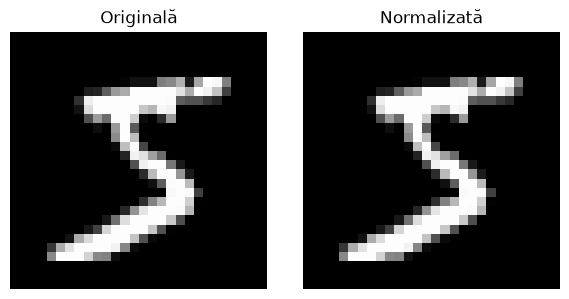

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(train_images[0], cmap="gray"); axes[0].set_title("Originală")
axes[1].imshow(train_images_normalized[0], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Normalizată")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

Interpretare: valorile numerice s-au schimbat prin normalizare, dar conținutul imaginii a rămas același.

## 7. Arhitectura

Modelul Dense compact este potrivit pentru rulare pe CPU: **784 → 128 → 64 → 32 → 64 → 128 → 784**. Codul latent are 32 de valori. Sigmoid la ieșire produce valori în [0, 1], ca pixelii normalizați.


In [80]:
input_dimension = train_images_flattened.shape[1]
latent_dimension = 32   # Câte numere are „rezumatul" imaginii.
encoder = keras.Sequential([   # Datele intră pe la un capăt și ies pe la celălalt.
    layers.Input(shape=(input_dimension,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(latent_dimension, activation="relu"), # relu - negativele devin 0
], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

Interpretare: Encoderul reduce 784 → 128 → 64 → 32. Straturile Dense învață combinații de pixeli, iar ReLU introduce neliniaritate.

In [81]:
decoder = keras.Sequential([  # straturi puse unul după altul, acum invers 
    layers.Input(shape=(latent_dimension,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(input_dimension, activation="sigmoid"),  # Ia orice număr și îl strânge între 0 și 1
], name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

Interpretare: Decoderul extinde codul latent la 784 de pixeli; sigmoid limitează ieșirea la [0, 1].

Analogie: ai rezumatul de 32 de cuvinte și rescrii povestea completă, de 784 de cuvinte. Nu va fi identică cu originalul, dar va avea aceeași idee. 

In [82]:
autoencoder = keras.Sequential([encoder, decoder], name="mnist_autoencoder")
autoencoder.summary()

Model: "mnist_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Interpretare: modelul complet aplică Encoderul, apoi Decoderul; intrarea și ieșirea au câte 784 valori.

## 8. Fluxul prin model

In [83]:
sample_images = test_images_flattened[:5]
sample_latent_vectors = encoder.predict(sample_images, verbose=0)
sample_reconstructions = decoder.predict(sample_latent_vectors, verbose=0)
print(f"Intrare: {sample_images.shape}")
print(f"Cod latent: {sample_latent_vectors.shape}")
print(f"Reconstrucție: {sample_reconstructions.shape}")

Intrare: (5, 784)
Cod latent: (5, 32)
Reconstrucție: (5, 784)


Interpretare: fiecare imagine de 784 valori devine un cod de 32 valori, apoi este decodată la 784 valori.

## 9. Compilarea

Adam ajustează ponderile. MSE măsoară diferența dintre pixeli. Modelul încearcă să minimizeze această eroare.

In [84]:
autoencoder.compile(optimizer="adam", loss="mse")
print("Autoencoderul a fost compilat cu Adam și MSE.")

Autoencoderul a fost compilat cu Adam și MSE.


Interpretare: modelul va compara imaginea reconstruită cu imaginea furnizată ca intrare.

MSE = media diferențelor pătratice dintre pixelii originali și cei refăcuți.
Un singur număr care spune cât de departe e imaginea refăcută de original.

Adam este algoritmul care decide cât de mult și în ce direcție se ajustează fiecare pondere.

## 10. Antrenarea

`x` este imaginea de intrare, iar `y` este aceeași imagine, folosită ca țintă. Validarea urmărește performanța pe imagini de test. 

In [85]:
history = autoencoder.fit(
    train_images_flattened, train_images_flattened,
    validation_data=(test_images_flattened, test_images_flattened),
    epochs=30, batch_size=128, verbose=1,
)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0486 - val_loss: 0.0270
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0234 - val_loss: 0.0202
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0190 - val_loss: 0.0170
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0167 - val_loss: 0.0154
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0153 - val_loss: 0.0144
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0143 - val_loss: 0.0135
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0134 - val_loss: 0.0127
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0126 - val_loss: 0.0120
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0120 - val_loss: 0.0115
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0115 - val_loss: 0.0111
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0111 - val_loss: 0.0107
Epoch 12/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step

Interpretare: Pe parcursul celor 30 de epoci, loss-ul de antrenare a scăzut de la 0.0486 la 0.0083, iar cel de validare de la 0.0270 la 0.0081. Cele două curbe scad împreună, iar diferența finală dintre ele este practic zero, deci nu apare supraînvățare.

## 11. Istoricul loss-ului

In [86]:
training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]
print(f"Loss final pe antrenare: {training_loss[-1]:.6f}")
print(f"Loss final pe validare: {validation_loss[-1]:.6f}")

Loss final pe antrenare: 0.008280
Loss final pe validare: 0.008135


Interpretare: acestea sunt MSE-urile de la ultima epocă pe datele de antrenare și validare. 

Două numere aproape identice = modelul se descurcă la fel de bine pe imagini pe care nu le-a văzut la antrenare.

## 12. Graficul loss

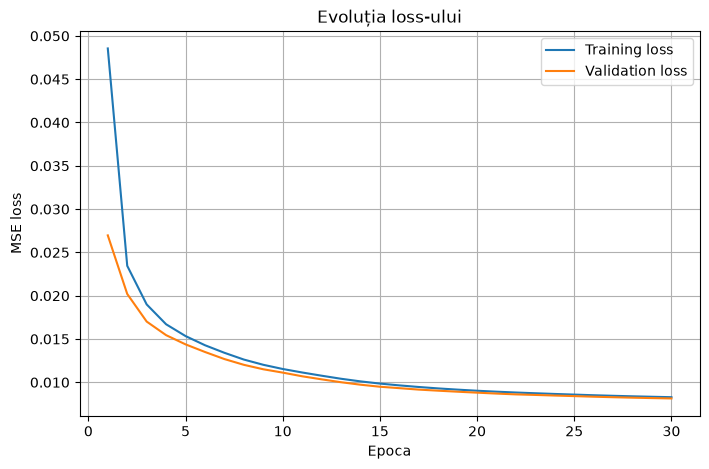

In [87]:
epochs_axis = range(1, len(training_loss) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, training_loss, label="Training loss")
plt.plot(epochs_axis, validation_loss, label="Validation loss")
plt.xlabel("Epoca"); plt.ylabel("MSE loss"); plt.title("Evoluția loss-ului")
plt.legend(); plt.grid(True); plt.show()

Interpretare: loss-ul în scădere indică reducerea erorii pe setul respectiv. 

## 13. Reconstruirea imaginilor

In [88]:
reconstructed_images = autoencoder.predict(test_images_flattened, batch_size=256, verbose=1)
print(f"Forma reconstrucțiilor aplatizate: {reconstructed_images.shape}")
reconstructed_images_reshaped = reconstructed_images.reshape(-1, 28, 28)
print(f"Forma după reshape: {reconstructed_images_reshaped.shape}")

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Forma reconstrucțiilor aplatizate: (10000, 784)
Forma după reshape: (10000, 28, 28)


Interpretare: 

dă cele 10.000 de imagini de test prin autoencoder și primește imaginile refăcute. Apoi le pune înapoi în forma de tabel 28 × 28, ca să poată fi afișate.

fiecare vector reconstruit conține 784 de pixeli și a fost reașezat într-o grilă de 28 × 28.

## 14. Originale și reconstrucții

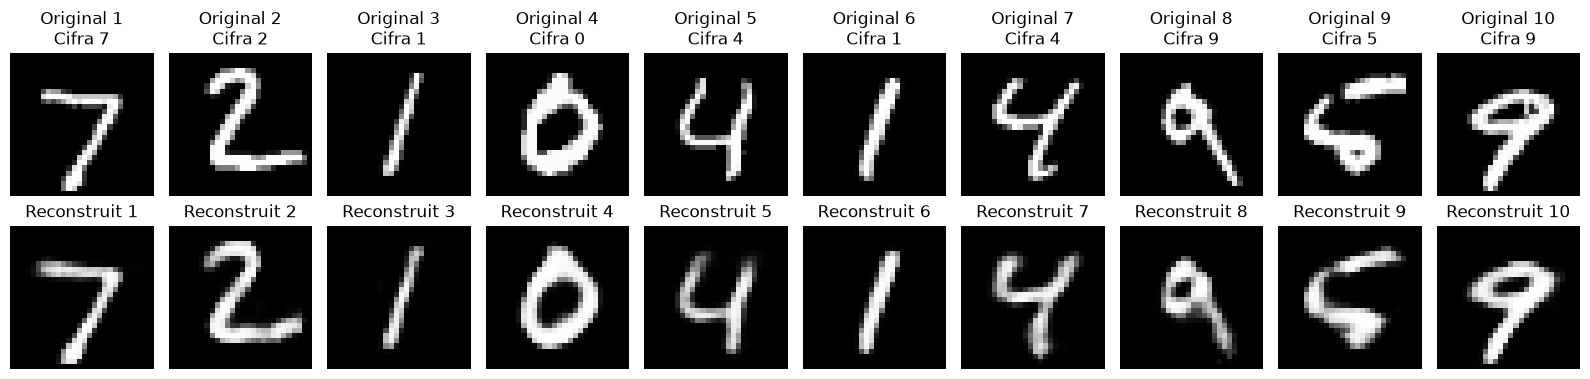

In [89]:
number_to_display = 10
fig, axes = plt.subplots(2, number_to_display, figsize=(16, 4))
for index in range(number_to_display):
    axes[0, index].imshow(test_images_normalized[index], cmap="gray", vmin=0, vmax=1)
    axes[0, index].set_title(f"Original {index+1}\nCifra {test_labels[index]}")
    axes[1, index].imshow(reconstructed_images_reshaped[index], cmap="gray", vmin=0, vmax=1)
    axes[1, index].set_title(f"Reconstruit {index+1}")
    axes[0, index].axis("off"); axes[1, index].axis("off")
axes[0, 0].set_ylabel("Originală"); axes[1, 0].set_ylabel("Reconstruită")
plt.tight_layout(); plt.show()

Interpretare: 
Imaginile reconstruite păstrează forma și identitatea cifrelor, toate cele 10 exemple fiind ușor de recunoscut. Diferențele apar la detalii: contururile sunt mai încețoșate, iar liniile subțiri și buclele mici (de exemplu la cifrele 4 și 5) sunt mai puțin clare. Aceasta este consecința comprimării fiecărei imagini de la 784 la 32 de valori, care păstrează trăsăturile principale, dar pierde detaliile fine.

## 15. Traseul unei singure imagini

Imagine inițială: (28, 28)
Vector aplatizat: (1, 784)
Vector latent: (1, 32)
Vector decodat: (1, 784)
Imagine reconstruită: (28, 28)


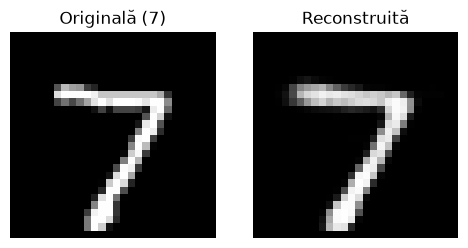

In [90]:
image_index = 0
single_image = test_images_flattened[image_index:image_index+1]
single_latent_vector = encoder.predict(single_image, verbose=0)
single_reconstruction = decoder.predict(single_latent_vector, verbose=0)
single_reconstruction_image = single_reconstruction.reshape(28, 28)
print(f"Imagine inițială: {test_images[image_index].shape}")
print(f"Vector aplatizat: {single_image.shape}")
print(f"Vector latent: {single_latent_vector.shape}")
print(f"Vector decodat: {single_reconstruction.shape}")
print(f"Imagine reconstruită: {single_reconstruction_image.shape}")
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
axes[0].imshow(test_images[image_index], cmap="gray"); axes[0].set_title(f"Originală ({test_labels[image_index]})")
axes[1].imshow(single_reconstruction_image, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Reconstruită")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

Interpretare: traseul este 28 × 28 → 784 → 32 → 784 → 28 × 28.

## 16. Reprezentarea latentă

In [91]:
latent_test_vectors = encoder.predict(test_images_flattened[:1000], batch_size=256, verbose=1)
print(f"Forma reprezentărilor latente: {latent_test_vectors.shape}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Forma reprezentărilor latente: (1000, 32)


Interpretare: 

4/4 = 1000 imagini în loturi de 256, deci 4 pași.
(1000, 32) = 1000 imagini, fiecare rezumată în 32 de numere.

spațiul latent comprimă imaginile. Deoarece are mai puține valori decât intrarea, unele detalii nu pot fi păstrate perfect.

## 17. MSE pentru setul de test

calculează un singur număr care spune cât de departe sunt imaginile refăcute de cele originale, pe toate cele 10.000 de imagini de test.

In [92]:
test_reconstruction_mse = np.mean(np.square(test_images_flattened - reconstructed_images))
print(f"MSE mediu pe imaginile de test: {test_reconstruction_mse:.6f}")

MSE mediu pe imaginile de test: 0.008135


Interpretare: MSE-ul mediu pe imaginile de test este de aproximativ 0.008, valoare apropiată de loss-ul final de validare. Aceasta arată că diferența medie dintre pixelii originali și cei reconstruiți este mică

--- 


---

# 18. Autoencoder variational (VAE)

Ideea: același Encoder → Decoder ca la autoencoderul clasic, cu 3 modificări:

Encoderul dă o zonă (centru + lărgime), nu un punct.
Din zonă se alege un punct random.
Eroarea are 2 părți, nu una.


## 18.1. Dimensiunea latentă și Sampling

definește un strat care alege un punct random dintr-o zonă. Zona e descrisă de centru (z_mean) și lărgime (z_log_var). Celula doar definește stratul, nu calculează nimic încă.


In [93]:
vae_latent_dimension = 2

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

print(f"Dimensiunea latentă aleasă pentru VAE: {vae_latent_dimension}")


Dimensiunea latentă aleasă pentru VAE: 2


Interpretare: 
- Sampling = alege un punct random dintr-o zonă.
- Formula: centru + lărgime × zgomot.
- z_mean = centrul, z_log_var = lărgimea în formă logaritmică.
- Random-ul stă în epsilon, ca rețeaua să poată fi antrenată.

Analogie:
- Autoencoderul clasic spune: „imaginea asta e exact în punctul X".
- VAE spune: „imaginea asta e prin zona X, cam pe aici".
- Decoderul primește un punct aruncat din acea zonă și trebuie să deseneze cifra corectă din oricare punct al zonei.
- Asta îl învață să fie flexibil, iar spațiul latent devine neted. De aceea VAE poate genera cifre noi, dacă îi dai un punct ales de tine.

## 18.2. Encoderul VAE

Ce face: construiește Encoderul VAE. El ia imaginea (784 valori) și dă 3 lucruri: centrul zonei (z_mean), lărgimea ei (z_log_var) și un punct ales din zonă (z_sample).

In [94]:
vae_encoder_input = layers.Input(shape=(input_dimension,), name="vae_encoder_input")
vae_hidden = layers.Dense(128, activation="relu")(vae_encoder_input)
vae_hidden = layers.Dense(64, activation="relu")(vae_hidden)
z_mean = layers.Dense(vae_latent_dimension, name="z_mean")(vae_hidden)
z_log_var = layers.Dense(vae_latent_dimension, name="z_log_var")(vae_hidden)
z_sample = Sampling(name="sampling")([z_mean, z_log_var])

vae_encoder = keras.Model(
    vae_encoder_input, [z_mean, z_log_var, z_sample], name="vae_encoder"
)
vae_encoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_encoder_input   │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 128)       │    100,480 │ vae_encoder_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 64)        │      8,256 │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ dense_29[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ dense_29[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 108,996 (425.77 KB)

 Trainable params: 108,996 (425.77 KB)

 Non-trainable params: 0 (0.00 B)

Interpretare: Encoderul VAE produce trei ieșiri de dimensiune 2: media, log-varianța și eșantionul latent utilizat pentru reconstrucție.

## 18.3. Decoderul VAE

Ce face: construiește Decoderul VAE. El primește un punct cu 2 coordonate și desenează din el o imagine de 784 de pixeli.

Sigmoid păstrează pixelii reconstruiți în [0, 1].

In [95]:
vae_decoder_input = layers.Input(shape=(vae_latent_dimension,), name="vae_decoder_input")
vae_decoder_hidden = layers.Dense(64, activation="relu")(vae_decoder_input)
vae_decoder_hidden = layers.Dense(128, activation="relu")(vae_decoder_hidden)
vae_decoder_output = layers.Dense(input_dimension, activation="sigmoid")(vae_decoder_hidden)
vae_decoder = keras.Model(vae_decoder_input, vae_decoder_output, name="vae_decoder")
vae_decoder.summary()

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_decoder_input (InputLayer)  │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,648 (428.31 KB)

 Trainable params: 109,648 (428.31 KB)

 Non-trainable params: 0 (0.00 B)

Interpretare: Decoderul reconstruiește o imagine vectorizată dintr-un singur punct latent de două coordonate.

## 18.4. Funcția obiectiv a VAE

lipește Encoderul și Decoderul VAE într-un singur model și îi spune cum să învețe: cum se calculează eroarea și cum se ajustează ponderile.

In [96]:
class VariationalAutoencoder(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)

    # Salvează Encoderul și Decoderul în model.
        self.encoder = encoder
        self.decoder = decoder
    # Creează 3 contoare care fac media erorilor pe o epocă
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")


    # Îi spune lui Keras care sunt cele 3 contoare
    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]


    # Definește cum se face propagarea înainte (forward pass) în model
    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)


    # Definește cum se calculează pierderea (loss) pentru o imagine sau un batch de imagini
    def _loss_components(self, images, training):
        z_mean, z_log_var, z = self.encoder(images, training=training)
        # Reconstrucția imaginilor din vectorii latenti
        reconstructions = self.decoder(z, training=training)
        pixel_bce = keras.backend.binary_crossentropy(images, reconstructions)
        reconstruction_loss = tf.reduce_mean(tf.reduce_sum(pixel_bce, axis=1))
        # Calculul pierderii KL Divergence - cât de mult se abate distribuția latentă de la o distribuție normală standard
        kl_per_image = -0.5 * tf.reduce_sum(
            1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
        )
        kl_loss = tf.reduce_mean(kl_per_image)
        return reconstruction_loss + kl_loss, reconstruction_loss, kl_loss


# Definește cum se face un pas de antrenare (train step) și un pas de testare (test step)
    def train_step(self, data):
        images = keras.utils.unpack_x_y_sample_weight(data)[0]
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self._loss_components(images, training=True)
        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

# Definește cum se face un pas de testare (test step)
    def test_step(self, data):
        images = keras.utils.unpack_x_y_sample_weight(data)[0]
        total_loss, reconstruction_loss, kl_loss = self._loss_components(images, training=False)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

vae = VariationalAutoencoder(vae_encoder, vae_decoder, name="mnist_vae")
vae.compile(optimizer=keras.optimizers.Adam())
_ = vae(tf.zeros((1, input_dimension)))
vae.summary()

Model: "mnist_vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_encoder (Functional)        │ ((None, 2), (None, 2), │       108,996 │
│                                 │ (None, 2))             │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vae_decoder (Functional)        │ (None, 784)            │       109,648 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,644 (854.08 KB)

 Trainable params: 218,644 (854.08 KB)

 Non-trainable params: 0 (0.00 B)

## 18.5. Verificarea ieșirilor VAE

Înainte de antrenare, urmărim formele celor trei ieșiri ale Encoderului și ale imaginii produse de Decoder.

In [97]:
vae_sample = test_images_flattened[:4]
vae_sample_mean, vae_sample_log_var, vae_sample_z = vae_encoder.predict(vae_sample, verbose=0)
vae_sample_output = vae_decoder.predict(vae_sample_z, verbose=0)
print(f"Forma intrării: {vae_sample.shape}")
print(f"Forma z_mean: {vae_sample_mean.shape}")
print(f"Forma z_log_var: {vae_sample_log_var.shape}")
print(f"Forma eșantionului z: {vae_sample_z.shape}")
print(f"Forma imaginii decodate: {vae_sample_output.shape}")

Forma intrării: (4, 784)
Forma z_mean: (4, 2)
Forma z_log_var: (4, 2)
Forma eșantionului z: (4, 2)
Forma imaginii decodate: (4, 784)


Interpretare: Fiecare imagine e rezumată în 2 numere pentru centru, 2 pentru lărgime și 2 pentru punctul ales.
Decoderul reface din cele 2 numere ale lui z toți cei 784 de pixeli.

## 18.6. Antrenarea VAE

VAE primește imaginile ca intrări; reconstrucția este calculată în interiorul modelului. Validarea folosește imaginile test. Afișăm separat loss-ul total, reconstrucția și componenta KL.

In [98]:
vae_history = vae.fit(
    train_images_flattened,
    validation_data=(test_images_flattened, test_images_flattened),
    epochs=30,
    batch_size=128,
    shuffle=True,
    verbose=1,
)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - kl_loss: 5.6338 - loss: 204.9491 - reconstruction_loss: 199.3154 - val_kl_loss: 4.3214 - val_loss: 177.7049 - val_reconstruction_loss: 173.3835
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - kl_loss: 4.7033 - loss: 172.3579 - reconstruction_loss: 167.6546 - val_kl_loss: 4.7291 - val_loss: 168.1156 - val_reconstruction_loss: 163.3865
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - kl_loss: 4.9504 - loss: 166.0382 - reconstruction_loss: 161.0877 - val_kl_loss: 5.1484 - val_loss: 163.3828 - val_reconstruction_loss: 158.2344
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - kl_loss: 5.1183 - loss: 162.2940 - reconstruction_loss: 157.1758 - val_kl_loss: 5.2045 - val_loss: 160.5322 - val_reconstruction_loss: 155.3278
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 5.2702 - loss: 159.7455 - reconstruction_loss: 154.4753 - val_kl_loss: 5.2673 - val_loss: 158.2078 - val_reconstruction_loss: 152.9405
Epoch 6/3

Interpretare: 

Valorile de aici (~153) nu se pot compara cu MSE-ul clasic (dif. orginal cu refăcut) (~0.008):

BCE (pedepsește greșelile mai mari) e însumat pe cei 784 de pixeli ale unei imagini, iar MSE e o medie pe pixel.
Au formule diferite și include și KL (cât de ordonat e spațiul latent).

## 18.7. Istoricul și graficul VAE

Loss total VAE la ultima epocă: 145.1764
Loss reconstrucție la ultima epocă: 138.9272
Loss KL la ultima epocă: 6.2491
Loss total VAE de validare la ultima epocă: 146.2454


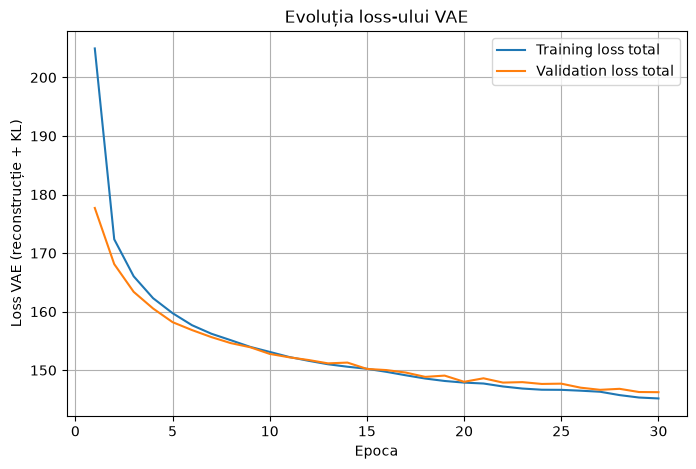

In [99]:
vae_training_total_loss = vae_history.history["loss"]
vae_validation_total_loss = vae_history.history["val_loss"]
vae_training_reconstruction_loss = vae_history.history["reconstruction_loss"]
vae_training_kl_loss = vae_history.history["kl_loss"]
print(f"Loss total VAE la ultima epocă: {vae_training_total_loss[-1]:.4f}")
print(f"Loss reconstrucție la ultima epocă: {vae_training_reconstruction_loss[-1]:.4f}")
print(f"Loss KL la ultima epocă: {vae_training_kl_loss[-1]:.4f}")
print(f"Loss total VAE de validare la ultima epocă: {vae_validation_total_loss[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(vae_training_total_loss) + 1), vae_training_total_loss, label="Training loss total")
plt.plot(range(1, len(vae_validation_total_loss) + 1), vae_validation_total_loss, label="Validation loss total")
plt.xlabel("Epoca"); plt.ylabel("Loss VAE (reconstrucție + KL)")
plt.title("Evoluția loss-ului VAE"); plt.legend(); plt.grid(True); plt.show()

## 18.8. Reconstrucțiile VAE și comparația vizuală

refac imaginile de test cu VAE, apoi desenează o grilă cu 3 rânduri: originalul, autoencoderul clasic și VAE, pe aceleași 10 cifre.

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Forma reconstrucțiilor VAE: (10000, 784)


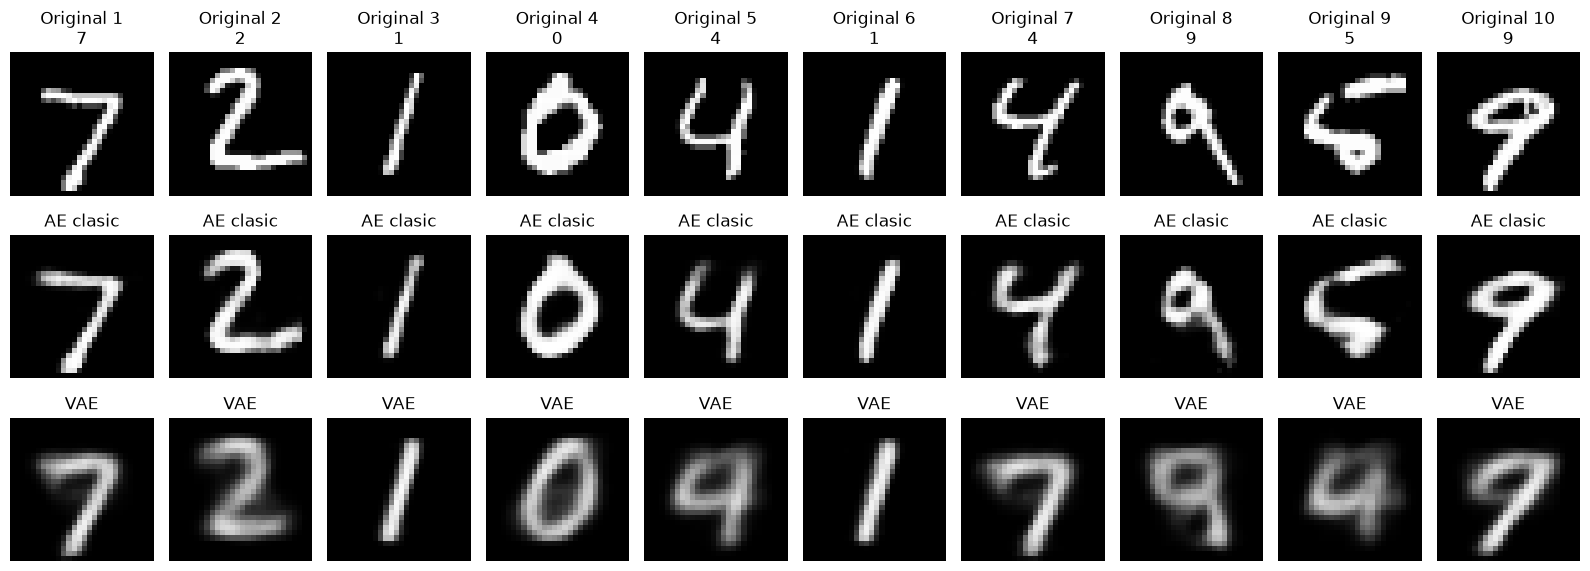

In [100]:
vae_test_mean, vae_test_log_var, _ = vae_encoder.predict(test_images_flattened, batch_size=256, verbose=1)
vae_reconstructed_images = vae_decoder.predict(vae_test_mean, batch_size=256, verbose=1)
vae_reconstructed_images_reshaped = vae_reconstructed_images.reshape(-1, 28, 28)
print(f"Forma reconstrucțiilor VAE: {vae_reconstructed_images.shape}")

fig, axes = plt.subplots(3, 10, figsize=(16, 6))
for index in range(10):
    axes[0, index].imshow(test_images_normalized[index], cmap="gray", vmin=0, vmax=1)
    axes[0, index].set_title(f"Original {index+1}\n{test_labels[index]}")
    axes[1, index].imshow(reconstructed_images_reshaped[index], cmap="gray", vmin=0, vmax=1)
    axes[1, index].set_title("AE clasic")
    axes[2, index].imshow(vae_reconstructed_images_reshaped[index], cmap="gray", vmin=0, vmax=1)
    axes[2, index].set_title("VAE")
    for row in range(3): axes[row, index].axis("off")
axes[0, 0].set_ylabel("Originală"); axes[1, 0].set_ylabel("AE clasic"); axes[2, 0].set_ylabel("VAE")
plt.tight_layout(); plt.show()

Interpretare: 

De ce e VAE mai slab aici?
- AE clasic păstrează 32 de valori per imagine.
- VAE păstrează doar 2 valori.
- Cu atât de puțină informație, Decoderul nu poate reface detaliile, iar cifrele asemănătoare ajung în zone apropiate din spațiul latent.
- Pe lângă asta, KL forțează zonele să rămână aproape de centru, ceea ce estompează diferențele fine.


## 18.9. Comparație numerică pe aceeași măsură

calculează aceeași măsură (MSE) pentru ambele modele, pe aceleași 10.000 de imagini de test. Așa se poate compara direct cât de bine reface fiecare imaginile.

In [101]:
vae_test_mse = np.mean(np.square(test_images_flattened - vae_reconstructed_images))
classic_test_mse = np.mean(np.square(test_images_flattened - reconstructed_images))
print("MSE calculat identic, pixel cu pixel, pe setul de test:")
print(f"Autoencoder clasic (latent 32): {classic_test_mse:.6f}")
print(f"VAE (latent 2, decodare din z_mean): {vae_test_mse:.6f}")
print("MSE mai mic înseamnă diferență numerică medie mai mică; nu surprinde singur toate aspectele vizuale.")

MSE calculat identic, pixel cu pixel, pe setul de test:
Autoencoder clasic (latent 32): 0.008135
VAE (latent 2, decodare din z_mean): 0.038850
MSE mai mic înseamnă diferență numerică medie mai mică; nu surprinde singur toate aspectele vizuale.


Interpretare: MSE oferă aceeași unitate de comparație pentru cele două ieșiri pe aceleași imagini. 

- AE clasic a învățat cu MSE (~0.008).
- VAE a învățat cu BCE + KL (~153).

Aici ambele sunt măsurate cu același MSE, deci comparația e corectă.



## 18.10. Vizualizarea spațiului latent VAE

desenează un grafic 2D în care fiecare punct e o imagine de test. Poziția punctului e centrul zonei ei (z_mean), iar culoarea arată ce cifră e.

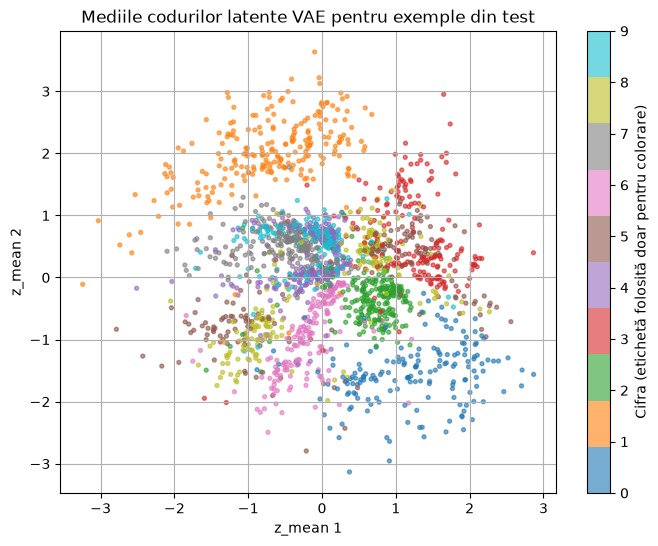

Puncte reprezentate: 2000


In [102]:
number_of_latent_points = 2000
latent_means_for_plot = vae_test_mean[:number_of_latent_points]
labels_for_plot = test_labels[:number_of_latent_points]
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_means_for_plot[:, 0], latent_means_for_plot[:, 1],
    c=labels_for_plot, s=8, alpha=0.6, cmap="tab10",
)
plt.xlabel("z_mean 1"); plt.ylabel("z_mean 2")
plt.title("Mediile codurilor latente VAE pentru exemple din test")
plt.colorbar(scatter, label="Cifra (etichetă folosită doar pentru colorare)")
plt.grid(True); plt.show()
print(f"Puncte reprezentate: {len(latent_means_for_plot)}")

Interpretare: Spațiul latent al VAE este compact și centrat în jurul originii, în concordanță cu regularizarea KL. Deși etichetele nu au fost folosite la antrenare, unele cifre formează grupuri distincte: 0 și 1 sunt bine separate, iar 2, 3 și 6 ocupă zone parțial separate. În schimb, cifrele 4, 7 și 9 se suprapun în zona centrală, iar 5 și 8 sunt împrăștiate. Aceste suprapuneri explică confuziile observate în reconstrucții. Cu doar două dimensiuni latente, VAE păstrează o structură utilă, dar nu separă complet clasele.

## 18.11. Generarea unor imagini noi

VAE inventează cifre noi, care nu există în setul de date.

- Se alege 10 puncte random în spațiul latent (2 coordonate fiecare).
- se dau Decoderului, fără Encoder și fără imagini reale.
- Decoderul desenează câte o imagine din fiecare punct.

KL a ținut spațiul latent în jurul lui (0, 0). Punctele random cad în aceeași zonă în care au stat imaginile reale, deci Decoderul știe ce să deseneze.

Forma punctelor latente generate: (10, 2)
Forma imaginilor generate: (10, 784)


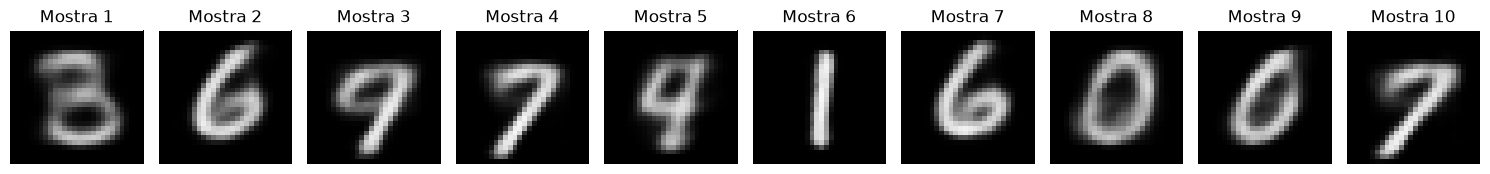

In [106]:
generated_latent_points = np.random.normal(size=(10, vae_latent_dimension)).astype("float32")
generated_images = vae_decoder.predict(generated_latent_points, verbose=0)
print(f"Forma punctelor latente generate: {generated_latent_points.shape}")
print(f"Forma imaginilor generate: {generated_images.shape}")
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for index, axis in enumerate(axes):
    axis.imshow(generated_images[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"Mostra {index+1}"); axis.axis("off")
plt.tight_layout(); plt.show()

## 18.12. Sinteza comparației

- AE clasic: cod determinist de 32 valori, antrenat cu MSE.
- VAE: cod probabilistic de 2 valori, antrenat cu BCE de reconstrucție + KL.
- MSE de test — AE clasic: 0.008135; VAE: 0.038850.
- Loss total VAE la ultima epocă: 145.1764; componentele reconstrucție=138.9272, KL=6.2491.
- AE clasic oferă un cod comprimat determinist; VAE regularizează latentul și permite generarea prin eșantionare.